JS05 Tugas - HDBSCAN pada dataset nyata (digits & iris), reduksi PCA/TSNE.

Sumber data: sklearn.datasets (load_digits 8x8 = 1797 sampel 64 fitur,
load_iris = 150 sampel 4 fitur). Snapshot CSV ditulis ke ../data/ sekali.

In [1]:
# Shim: notebook tidak punya __file__, kode ini warisan script .py.
import os
__file__ = os.path.abspath("tugas_hdbscan.ipynb")
print("base:", os.path.dirname(__file__))

base: C:\code\pemmes26\js05-klasterisasi-hierarki\tugas


In [2]:
from pathlib import Path

import matplotlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import HDBSCAN
from sklearn.datasets import load_digits, load_iris
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (adjusted_rand_score, davies_bouldin_score,
                             normalized_mutual_info_score, silhouette_score)
from sklearn.preprocessing import StandardScaler

DATA = Path(__file__).resolve().parent.parent / "data"
OUT = Path(__file__).resolve().parent / "output"
DATA.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)
ROWS = []

[Tugas] HDBSCAN pada dataset nyata (fitur mentah, min_cluster_size=5)



=== digits (n=1797, d=64, fitur=raw, min_cluster_size=5) ===
  jumlah cluster : 21
  noise (-1)     : 493 (27.43%)
  silhouette     : 0.0721
  Davies-Bouldin : 1.9427
  ARI vs label   : 0.4886
  NMI vs label   : 0.7365
  ukuran cluster : -1:493, 0:5, 1:11, 2:176, 3:148, 4:27, 5:148, 6:160, 7:14, 8:8, 9:164, 10:7, 11:22, 12:49, 13:8, 14:113, 15:82, 16:35, 17:43, 18:9, 19:67, 20:8
  modus kelas per cluster: 0->2(5/5), 1->7(11/11), 2->0(175/176), 3->7(148/148), 4->1(27/27), 5->2(148/148), 6->4(160/160), 7->9(14/14), 8->9(7/8), 9->6(164/164), 10->3(7/7), 11->8(22/22), 12->1(48/49), 13->8(8/8), 14->3(113/113), 15->9(82/82), 16->5(35/35), 17->5(43/43), 18->5(9/9), 19->1(67/67), 20->8(8/8)


  -> output/tugas_digits_pca_tsne.png

=== iris (n=150, d=4, fitur=raw, min_cluster_size=5) ===
  jumlah cluster : 2
  noise (-1)     : 0 (0.00%)
  silhouette     : 0.6867
  Davies-Bouldin : 0.3828
  ARI vs label   : 0.5681
  NMI vs label   : 0.7337
  ukuran cluster : 0:50, 1:100
  modus kelas per cluster: 0->0(50/50), 1->1(50/100)


  -> output/tugas_iris_pca_tsne.png

[Sensitivitas] digits: min_cluster_size 10/15/25



=== digits (n=1797, d=64, fitur=raw, min_cluster_size=10) ===
  jumlah cluster : 12
  noise (-1)     : 819 (45.58%)
  silhouette     : 0.0396
  Davies-Bouldin : 1.8838
  ARI vs label   : 0.2812
  NMI vs label   : 0.6435
  ukuran cluster : -1:819, 0:173, 1:134, 2:19, 3:134, 4:112, 5:163, 6:25, 7:71, 8:21, 9:76, 10:30, 11:20
  modus kelas per cluster: 0->0(173/173), 1->7(134/134), 2->1(19/19), 3->4(134/134), 4->2(112/112), 5->6(163/163), 6->5(25/25), 7->1(67/71), 8->1(21/21), 9->3(76/76), 10->9(29/30), 11->5(20/20)



=== digits (n=1797, d=64, fitur=raw, min_cluster_size=15) ===
  jumlah cluster : 11
  noise (-1)     : 903 (50.25%)
  silhouette     : 0.0183
  Davies-Bouldin : 1.9712
  ARI vs label   : 0.2172
  NMI vs label   : 0.5948
  ukuran cluster : -1:903, 0:17, 1:128, 2:171, 3:119, 4:83, 5:146, 6:98, 7:18, 8:15, 9:35, 10:64
  modus kelas per cluster: 0->1(17/17), 1->7(128/128), 2->0(171/171), 3->4(119/119), 4->2(83/83), 5->6(146/146), 6->1(85/98), 7->5(18/18), 8->5(15/15), 9->9(34/35), 10->3(64/64)



=== digits (n=1797, d=64, fitur=raw, min_cluster_size=25) ===
  jumlah cluster : 7
  noise (-1)     : 979 (54.48%)
  silhouette     : 0.0414
  Davies-Bouldin : 2.1651
  ARI vs label   : 0.1715
  NMI vs label   : 0.5284
  ukuran cluster : -1:979, 0:124, 1:91, 2:164, 3:147, 4:171, 5:67, 6:54
  modus kelas per cluster: 0->7(124/124), 1->4(91/91), 2->0(164/164), 3->6(147/147), 4->3(85/171), 5->1(62/67), 6->2(54/54)

[Pembanding] digits: standardisasi dan PCA-10 sebelum clustering



=== digits (n=1797, d=64, fitur=std, min_cluster_size=5) ===
  jumlah cluster : 21
  noise (-1)     : 839 (46.69%)
  silhouette     : -0.0419
  Davies-Bouldin : 2.0271
  ARI vs label   : 0.2122
  NMI vs label   : 0.5792
  ukuran cluster : -1:839, 0:5, 1:21, 2:5, 3:175, 4:124, 5:10, 6:7, 7:101, 8:6, 9:7, 10:67, 11:12, 12:8, 13:5, 14:131, 15:16, 16:5, 17:141, 18:14, 19:72, 20:26
  modus kelas per cluster: 0->7(5/5), 1->1(20/21), 2->2(5/5), 3->0(174/175), 4->7(124/124), 5->5(10/10), 6->9(7/7), 7->4(101/101), 8->4(6/6), 9->9(7/7), 10->2(67/67), 11->5(12/12), 12->5(8/8), 13->3(5/5), 14->3(77/131), 15->5(16/16), 16->8(5/5), 17->6(141/141), 18->8(14/14), 19->1(68/72), 20->1(26/26)

=== digits (n=1797, d=10, fitur=std+pca10, min_cluster_size=5) ===
  jumlah cluster : 22
  noise (-1)     : 887 (49.36%)
  silhouette     : -0.0842
  Davies-Bouldin : 1.6882
  ARI vs label   : 0.2026
  NMI vs label   : 0.5664
  ukuran cluster : -1:887, 0:20, 1:132, 2:20, 3:7, 4:46, 5:132, 6:152, 7:154, 8:5, 9:43, 


[ringkasan] tabel metrik -> output/tugas_metrik.csv
dataset     fitur  min_cluster_size  n_sampel  n_cluster  n_noise  pct_noise  silhouette  davies_bouldin      ari      nmi
 digits       raw                 5      1797         21      493      27.43    0.072079        1.942736 0.488639 0.736532
   iris       raw                 5       150          2        0       0.00    0.686735        0.382753 0.568116 0.733680
 digits       raw                10      1797         12      819      45.58    0.039615        1.883807 0.281154 0.643479
 digits       raw                15      1797         11      903      50.25    0.018312        1.971224 0.217241 0.594837
 digits       raw                25      1797          7      979      54.48    0.041438        2.165137 0.171545 0.528401
 digits       std                 5      1797         21      839      46.69   -0.041854        2.027052 0.212156 0.579178
 digits std+pca10                 5      1797         22      887      49.36   -0.0841

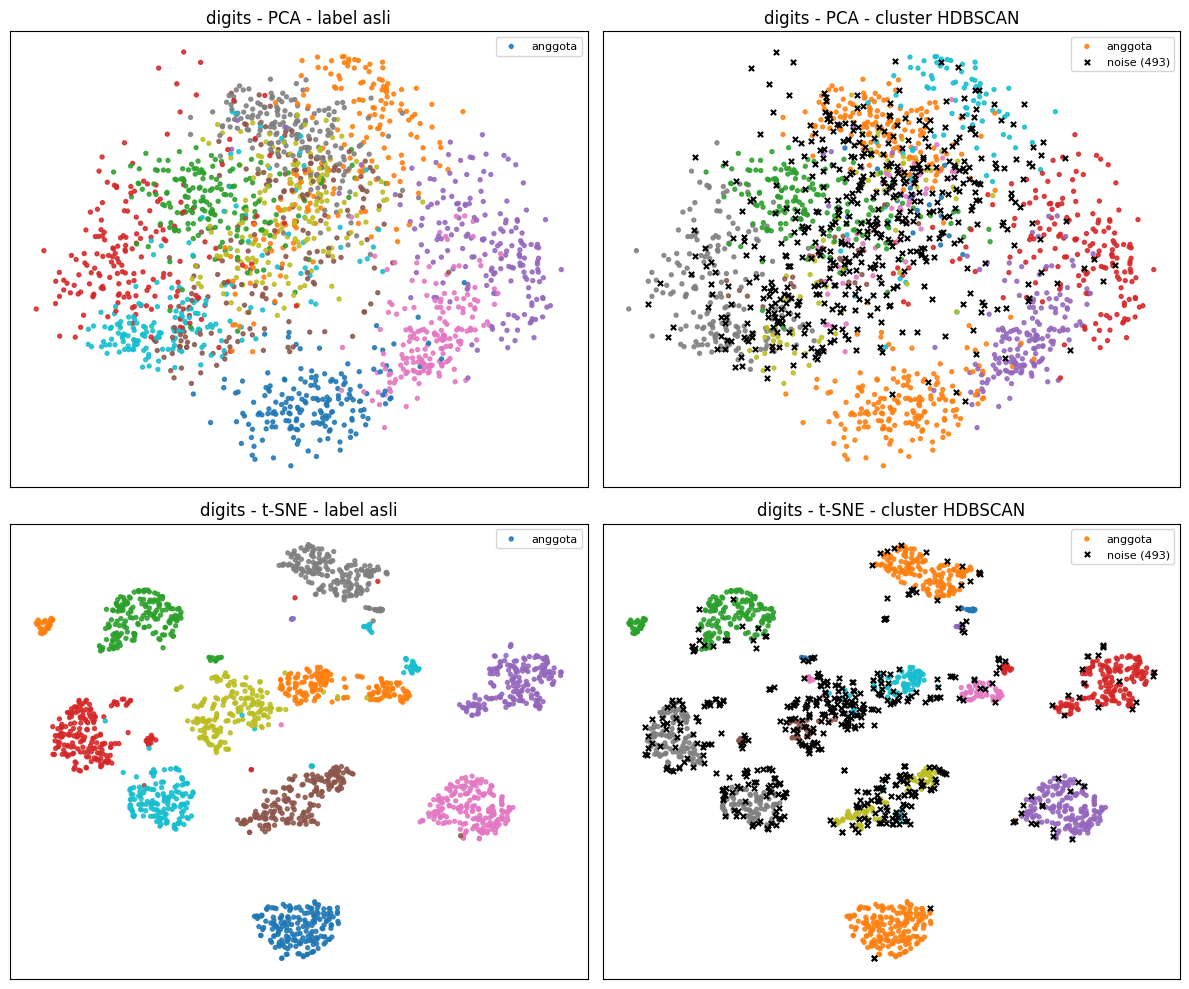

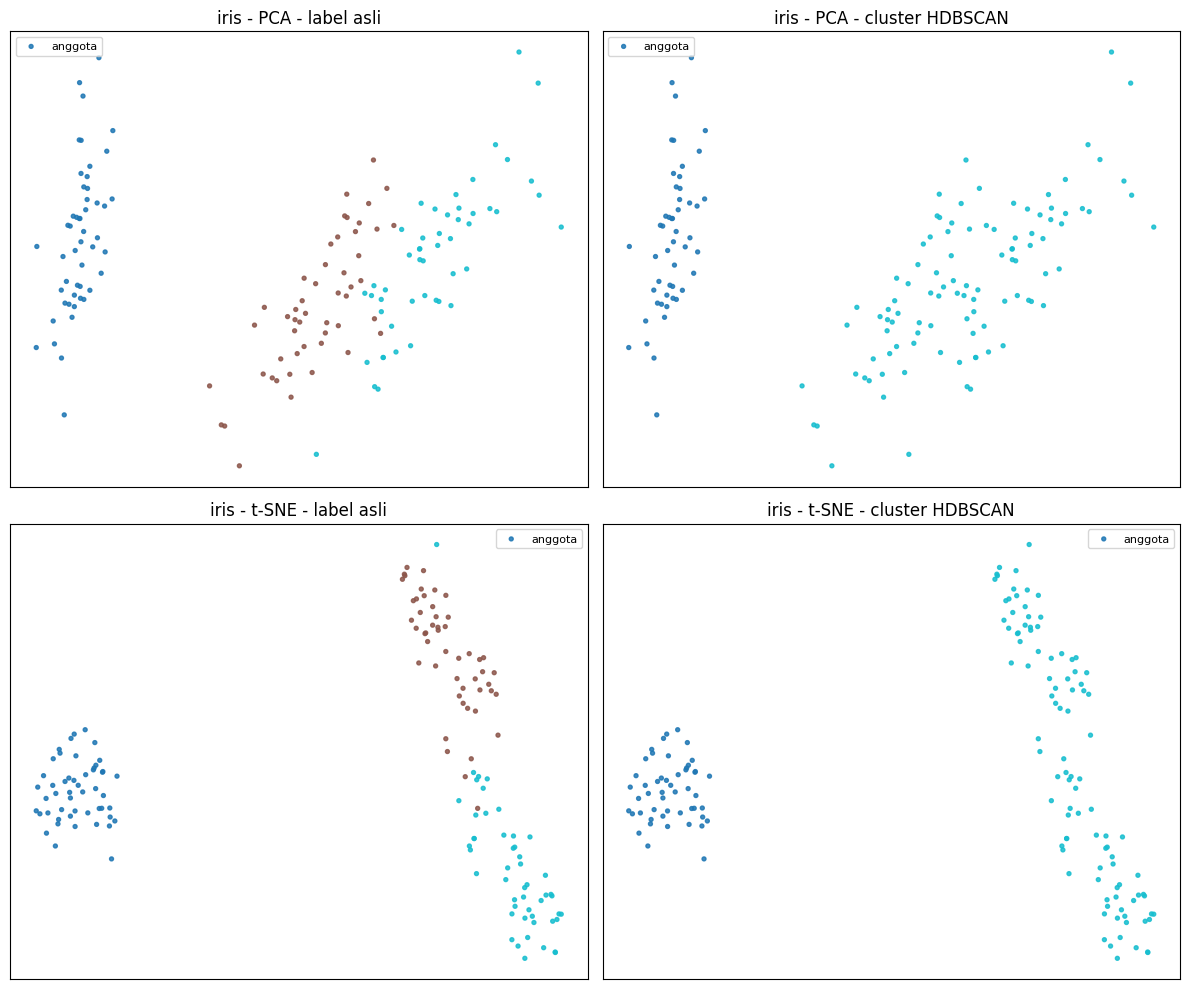

In [3]:
def load(name):
    """Ambil dataset sklearn + simpan snapshot CSV di data/ bila belum ada."""
    bunch = load_digits() if name == "digits" else load_iris()
    path = DATA / f"{name}.csv"
    if not path.exists():
        df = pd.DataFrame(bunch.data, columns=bunch.feature_names)
        df["target"] = bunch.target
        df.to_csv(path, index=False)
        print(f"  snapshot -> data/{name}.csv ({df.shape[0]}x{df.shape[1]})")
    return bunch.data, bunch.target


def run(name, scale=False, min_cluster_size=5, pca_dim=None):
    X, y = load(name)
    Xv = StandardScaler().fit_transform(X) if scale else X
    Xs = PCA(pca_dim, random_state=0).fit_transform(Xv) if pca_dim else Xv
    prep = ("std" if scale else "raw") + (f"+pca{pca_dim}" if pca_dim else "")
    hdb = HDBSCAN(min_cluster_size=min_cluster_size).fit(Xs)
    lab = hdb.labels_
    n_clusters = len(set(lab)) - (1 if -1 in lab else 0)
    n_noise = int((lab == -1).sum())

    # silhouette/DBI pada ruang fitur penuh (standardized); noise ikut dihitung
    sil = silhouette_score(Xs, lab) if 1 < n_clusters < len(Xs) else np.nan
    dbi = davies_bouldin_score(Xs, lab) if 1 < n_clusters < len(Xs) else np.nan
    ari = adjusted_rand_score(y, lab)
    nmi = normalized_mutual_info_score(y, lab)

    print(f"\n=== {name} (n={len(Xs)}, d={Xs.shape[1]}, fitur={prep}, "
          f"min_cluster_size={min_cluster_size}) ===")
    print(f"  jumlah cluster : {n_clusters}")
    print(f"  noise (-1)     : {n_noise} ({n_noise / len(Xs):.2%})")
    print(f"  silhouette     : {sil:.4f}")
    print(f"  Davies-Bouldin : {dbi:.4f}")
    print(f"  ARI vs label   : {ari:.4f}")
    print(f"  NMI vs label   : {nmi:.4f}")
    sizes = pd.Series(lab).value_counts().sort_index()
    print("  ukuran cluster : " + ", ".join(f"{k}:{v}" for k, v in sizes.items()))

    # komposisi digit/kelas tiap cluster -> cek kesesuaian label asli
    tab = pd.crosstab(pd.Series(lab, name="cluster"), pd.Series(y, name="kelas"))
    print("  modus kelas per cluster: " + ", ".join(
        f"{c}->{tab.loc[c].idxmax()}({tab.loc[c].max()}/{tab.loc[c].sum()})"
        for c in tab.index if c != -1))

    ROWS.append(dict(dataset=name, fitur=prep,
                     min_cluster_size=min_cluster_size, n_sampel=len(Xs),
                     n_cluster=n_clusters, n_noise=n_noise,
                     pct_noise=round(100 * n_noise / len(Xs), 2),
                     silhouette=sil, davies_bouldin=dbi, ari=ari, nmi=nmi))
    return Xs, y, lab


def plots(name, Xs, y, lab):
    pca = PCA(n_components=2, random_state=0)
    Xp = pca.fit_transform(Xs)
    tsne = TSNE(n_components=2, perplexity=30, init="pca",
                random_state=0).fit_transform(Xs)

    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    for row, (emb, tag) in enumerate([(Xp, "PCA"), (tsne, "t-SNE")]):
        for col, (labels, title) in enumerate([(y, "label asli"),
                                              (lab, "cluster HDBSCAN")]):
            ax = axes[row, col]
            m = labels == -1
            ax.scatter(emb[~m, 0], emb[~m, 1], c=labels[~m], cmap="tab10",
                       s=8, alpha=0.85, label="anggota")
            if m.any():
                ax.scatter(emb[m, 0], emb[m, 1], c="k", marker="x", s=14,
                           label=f"noise ({m.sum()})")
            ax.set_title(f"{name} - {tag} - {title}")
            ax.set_xticks([])
            ax.set_yticks([])
            ax.legend(loc="best", fontsize=8)
    fig.tight_layout()
    fig.savefig(OUT / f"tugas_{name}_pca_tsne.png", dpi=110)
    print(f"  -> output/tugas_{name}_pca_tsne.png")


print("[Tugas] HDBSCAN pada dataset nyata (fitur mentah, min_cluster_size=5)")
for name in ["digits", "iris"]:
    _, y, lab = run(name)
    plots(name, load(name)[0], y, lab)

print("\n[Sensitivitas] digits: min_cluster_size 10/15/25")
for mcs in [10, 15, 25]:
    run("digits", min_cluster_size=mcs)

print("\n[Pembanding] digits: standardisasi dan PCA-10 sebelum clustering")
run("digits", scale=True, min_cluster_size=5)
run("digits", scale=True, min_cluster_size=5, pca_dim=10)
run("iris", scale=True, min_cluster_size=5)

df = pd.DataFrame(ROWS)
df.to_csv(OUT / "tugas_metrik.csv", index=False)
print("\n[ringkasan] tabel metrik -> output/tugas_metrik.csv")
print(df.to_string(index=False))

# ---- penilaian otomatis: apakah cluster cocok dengan label asli? ----
dig = df[(df.dataset == "digits") & (df.fitur == "raw")
         & (df.min_cluster_size == 5)].iloc[0]
assert dig.n_cluster >= 2 and 0 <= dig.ari <= 1
print(f"\n[check] digits ARI={dig.ari:.4f} NMI={dig.nmi:.4f} -> "
      f"{'cocok sebagian' if dig.nmi > 0.5 else 'tidak cocok'} dengan label asli")